# 01 · Setup, dataset, EDA and the fixed test set

**Task:** 3-class sentiment (positive / neutral / negative) of YouTube comments on the FlipTop
battle *Loonie & Abra vs Shehyee & Smugglaz* (video `gyIxD5K4lUo`).
Comments are mostly **Tagalog**, some **English**, many **Taglish** (both in one sentence), full of slang,
misspellings, laughter ("HAHAHA"), emoji and profanity.

This notebook:
1. loads the raw scrape (`data/youtube_comments_scraper.py` → `data/raw/`)
2. cleans it (`notebooks/src/cleaning.py`) and saves `data/processed/comments_clean.csv`
3. describes the hand-labelled sample (`data/labels/labeled_comments.csv`)
4. makes the **fixed, stratified train / test split** (seed 42, test = 300 comments)
5. runs the data check from the guidelines: class balance, average length, 10 examples per class

In [1]:
import sys, pathlib
NB_DIR = pathlib.Path.cwd().resolve()
if NB_DIR.name != "notebooks":        # Jupyter was started in the repo root instead of notebooks/
    NB_DIR = NB_DIR / "notebooks"
ROOT = NB_DIR.parent                  # repo root (data/, results/, prompts.md ...)
sys.path.insert(0, str(NB_DIR))       # so "from src import ..." finds notebooks/src/

import pandas as pd
import matplotlib.pyplot as plt

from src import config, data
from src.profanity import mask, mask_frame     # curse words are masked in everything shown
from src.cleaning import basic_clean, for_vader, normalize, tokenize, clean_dataframe

pd.set_option("display.max_colwidth", 120)
LABELS = config.LABELS
COLORS = {"negative": "#b4413c", "neutral": "#8a8f98", "positive": "#2f7d4f"}

## 0. Working environment

Checks that every package the project needs is installed (`pip install -r requirements.txt`).

In [2]:
import platform, importlib
print("Python", platform.python_version())
for pkg in ["pandas", "numpy", "sklearn", "matplotlib", "nltk", "vaderSentiment",
            "anthropic", "dotenv", "wordcloud"]:
    try:
        module = importlib.import_module(pkg)
        print(f"  {pkg:15s} {getattr(module, '__version__', 'installed')}")
    except ImportError:
        print(f"  {pkg:15s} NOT INSTALLED -> pip install -r requirements.txt")

Python 3.14.3
  pandas          3.0.5
  numpy           2.5.2
  sklearn         1.9.1
  matplotlib      3.11.1
  nltk            3.10.4
  vaderSentiment  installed
  anthropic       2.5.0
  dotenv          installed
  wordcloud       1.9.6


## 1. Raw data

In [3]:
raw = pd.read_csv(config.RAW_FILE)
print(raw.shape)
print("top-level comments:", (~raw["is_reply"]).sum(), "| replies:", raw["is_reply"].sum())
mask_frame(raw.drop(columns=["author"]).head(3))      # author names are never shown

(78566, 9)
top-level comments: 69237 | replies: 9329


,comment_id,parent_id,is_reply,text,like_count,published_at,updated_at,video_id
0,Ugw_cUI-GsxwRKBemId4AaABAg,NaN,False,Sheeesh,0,2026-11-05 19:50:07+00:00,2026-11-05T19:50:07Z,gyIxD5K4lUo
1,Ugys6pcWdp8UbYrdpSp4AaABAg,NaN,False,Once a year pinapanuod ko to!,0,2026-11-05 07:13:22+00:00,2026-11-05T07:13:22Z,gyIxD5K4lUo
2,Ugz7cuTpBw2eOBLV4kZ4AaABAg,NaN,False,2026,0,2026-11-05 02:36:41+00:00,2026-11-05T02:36:41Z,gyIxD5K4lUo


## 2. Cleaning

One raw comment becomes **three versions**, because each tier needs something different:

| column | used by | what happens |
|---|---|---|
| `text_clean` | Tier 3 (LLM) | unicode fix, remove URLs and @mentions, collapse spaces. Case, punctuation and emoji are kept - the LLM understands them. |
| `text_vader` | Tier 1 (VADER) | `text_clean` + Taglish spelling fixes (`lufet → lupet`, `hnd → hindi`), laughter → `haha`, `pero` / `kaso` → `but` so VADER's *but*-rule works. **Capitals are kept** because VADER treats ALL CAPS as emphasis. |
| `text_norm` | Tier 2 (NLTK + Naive Bayes) | lowercase, emoji → words (🔥 → `fire`, 😂 → `haha`), timestamps → `timestamp`, years → `year`, stretched letters cut (`grabeeee → grabe`), slang / misspellings / battler nicknames mapped to one spelling, multi-word phrases joined (`p****g i*a mo → t*****a`, `walang kwenta → walang_kwenta`). |

For the bag-of-words model we also mark **negation**: the two words after a Tagalog or English negator
(`hindi`, `wala`, `huwag`, `not` …) get a `NEG_` prefix, so *"hindi magaling"* becomes `hindi NEG_magaling`
and the model can learn it is the opposite of `magaling`.

In [4]:
examples = [
    "Grabe ang LUPEEET ni smugg 🔥🔥",
    "hnd nmn tlga magaling c sheyee, pabuhat lng kay smug 😂",
    "2024 na pinapanood ko pa rin to HAHAHAHA",
    "32:10 grabe yung rebuttal!!! @someone https://youtu.be/x",
    "Ganda ng laban pero luto",
]
mask_frame(pd.DataFrame({
    "raw": examples,
    "text_vader": [for_vader(t) for t in examples],
    "text_norm": [normalize(t) for t in examples],
    "tokens (NEG_ marked)": [" ".join(tokenize(normalize(t), drop_stopwords=False)) for t in examples],
}))

,raw,text_vader,text_norm,tokens (NEG_ marked)
0,Grabe ang LUPEEET ni smugg 🔥🔥,Grabe ang LUPET ni smugglaz 🔥🔥,grabe ang lupet ni smugglaz fire fire,grabe ang lupet ni smugglaz fire fire
1,"hnd nmn tlga magaling c sheyee, pabuhat lng kay smug 😂","hindi naman talaga magaling c shehyee, pabuhat lang kay smugglaz 😂",hindi naman talaga magaling si shehyee pabuhat lang kay smugglaz haha,hindi naman talaga NEG_magaling si NEG_shehyee pabuhat lang kay smugglaz haha
2,2024 na pinapanood ko pa rin to HAHAHAHA,2024 na pinapanood ko pa rin to haha,year na pinapanood ko pa rin to haha,year na pinapanood ko pa rin to haha
3,32:10 grabe yung rebuttal!!! @someone https://youtu.be/x,32:10 grabe yung rebuttal!!!,timestamp grabe yung rebuttal,timestamp grabe yung rebuttal
4,Ganda ng laban pero luto,Ganda ng laban but luto,ganda ng laban pero luto,ganda ng laban pero luto


In [5]:
clean, log = clean_dataframe(raw)
clean.to_csv(config.CLEAN_FILE, index=False)
pd.Series(log, name="rows").to_frame()

,rows
raw_rows,78566
after_drop_empty,78552
after_drop_no_content,76865
after_drop_duplicates,68098
model_pool,67002


- **empty**: comments with no text
- **no content**: only symbols / numbers (e.g. "1st", "....")
- **duplicates**: same text after normalising (spam like "haha", copy-pasted bars) - the most-liked copy is kept
- **model pool**: rows that are not empty after normalising and at most 400 characters (very long comments are usually pasted lyrics)

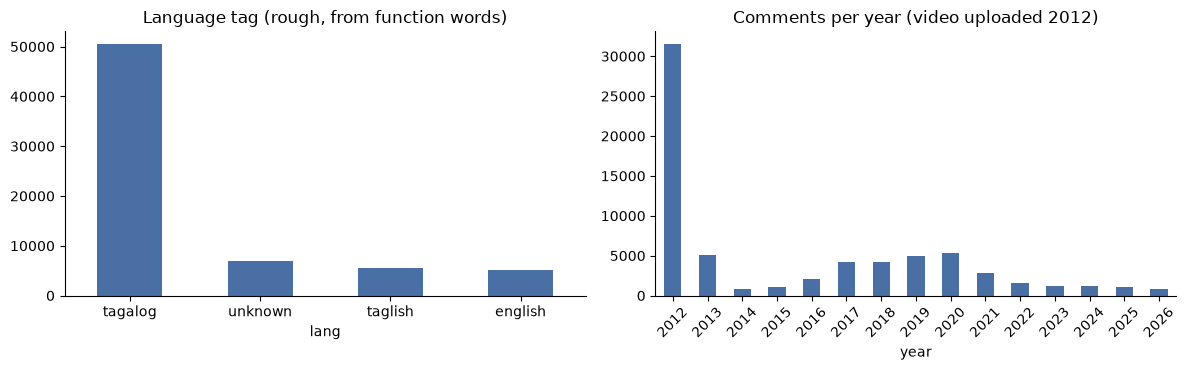

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
clean["lang"].value_counts().plot.bar(ax=axes[0], color="#4a6fa5", rot=0)
axes[0].set_title("Language tag (rough, from function words)")
clean["year"].value_counts().sort_index().plot.bar(ax=axes[1], color="#4a6fa5", rot=45)
axes[1].set_title("Comments per year (video uploaded 2012)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(config.CHARTS / "data_language_and_year.png", dpi=150)
plt.show()

## 3. The labelled sample

YouTube comments have no sentiment labels, so a sample had to be labelled by hand:

- **1,000 comments** drawn at random (seed 42) from the model pool
- labelled with the rules in [`data/labels/LABELING_GUIDE.md`](../data/labels/LABELING_GUIDE.md)
- first-pass labels were produced by Claude (Opus) acting as annotator; the column `reviewed` is there so a
  human can check and correct them. **Because Tier 3 is also a Claude model, review at least the 300 test
  rows before trusting the Tier 3 score** - otherwise the LLM is partly graded against its own family's opinion.

In [7]:
lab = pd.read_csv(config.LABELED_FILE, keep_default_na=False)
print(len(lab), "labelled comments")
pd.crosstab(lab["lang"], lab["label"], margins=True)

1000 labelled comments


label,negative,neutral,positive,All
lang,,,,
english,8,24,42,74
tagalog,384,156,228,768
taglish,23,21,32,76
unknown,20,39,23,82
All,435,240,325,1000


## 4. Fixed train / test split

Stratified on the label, `random_state = 42`, test set = **300 comments**. Every model in notebooks 02-04
is scored on exactly these 300 rows (saved to `data/processed/test_300.csv`). Only the Tier 2 model is
*trained* (on the other 700); VADER and the LLM never see the training data.

In [8]:
train, test = data.make_split()
balance = pd.DataFrame({
    "train": train["label"].value_counts(),
    "test": test["label"].value_counts(),
}).reindex(LABELS)
balance["train %"] = (balance["train"] / balance["train"].sum() * 100).round(1)
balance["test %"] = (balance["test"] / balance["test"].sum() * 100).round(1)
balance

,train,test,train %,test %
label,,,,
negative,304,131,43.4,43.7
neutral,168,72,24.0,24.0
positive,228,97,32.6,32.3


## 5. Data check

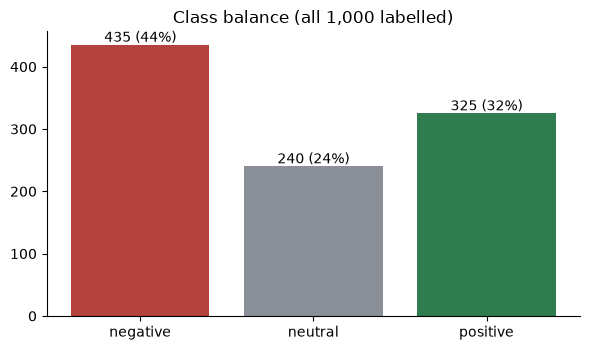

,n_chars,n_tokens
label,,
negative,84.5,15.0
neutral,58.5,10.5
positive,60.9,10.8


In [21]:
fig, ax = plt.subplots(figsize=(6, 3.6))
counts = lab["label"].value_counts().reindex(LABELS)
ax.bar(LABELS, counts, color=[COLORS[l] for l in LABELS])
for i, v in enumerate(counts):
    ax.text(i, v + 5, f"{v} ({v / len(lab):.0%})", ha="center")
ax.set_title("Class balance (all 1,000 labelled)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(config.CHARTS / "data_class_balance.png", dpi=150)
plt.show()

lab.groupby("label")[["n_chars", "n_tokens"]].mean().round(1).reindex(LABELS)

Negative is the largest class: a lot of this comment section is fans of one team insulting the other
team, the judges, or each other. Neutral comments are the shortest ("2024 still watching?",
"title ng intro song?"). Because the classes are not balanced, **macro-F1** (the average of the
three per-class F1 scores) is the main metric - accuracy alone would reward a model that just says
"negative" a lot.

**10 examples per class:**

In [22]:
for label in LABELS:
    print(f"\n===== {label.upper()} =====")
    for t in lab[lab["label"] == label].sample(10, random_state=1)["text_clean"]:
        print(" -", mask(t[:140]))


===== NEGATIVE =====
 - Nakagulo lang dito si abra haha parang mas mganda pa solo ni loonie
 - akaLA mo paq naq suOt anq rapeR nanq qanyan nakakamanqha ? G**O mukha kanq boss sa Call CenteR na bakLA ! ?
 - si boy bingot may bigote na!!!
 - mukang t***a c target sa likod,,
 - taguro twin Sila smugglaz tas sheyee💔🥀
 - Anong lUto ?? klaro naman eh talo sila LOonie kasi weak yung PunchLines Nla !! wag kang mag-angas
 - G**o p****g i*a mo
 - mga tira ni Loonie at Abra sama pamilya at bastos.. hindi tulad ni Shehyee at Smugglaz tira dun sa dalawa lang..
 - LOONIE - AT MAKUKUHA NYO PA ATA ANG 150K OH AYAN MGA B****G L/A FANS UNG IDOL NYO NA MISMO UMAMIN NA MATATALO SILA
 - t**g i*a kala ko magandang laban a*f tagal ko hinantay to ano ba pinag gagawa nyo abra loonie ? sayang lang pinag hirapan nyo

===== NEUTRAL =====
 - up july 23 2022
 - Machine Gun ah ok
 - wala naman matalas na icepick baka matilos meron😂😂😂
 - suplado title non irerelease nila yung kanta pag katapos ng dospordos
 - relax 

### Word cloud - all comments

Same style as the airline-tweets reference: one cloud of every comment in the model pool (67,000),
bigger word = more frequent. It uses `text_norm`, so spelling variants are already merged
(`lufet` / `lupit` → `lupet`, `sheyee` → `shehyee`). Common Tagalog / English function words, laughter
(`haha`) and the `year` / `timestamp` placeholders are removed, otherwise they would fill the whole cloud.

Needs `pip install wordcloud`.

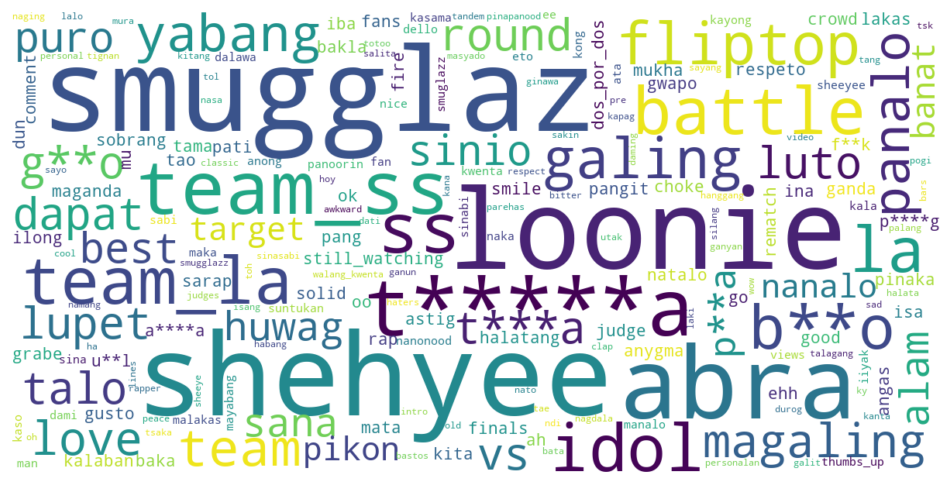

In [11]:
from collections import Counter
from wordcloud import WordCloud, STOPWORDS as WC_STOPWORDS
from src.cleaning import STOPWORDS as TAGLISH_STOPWORDS

FILLER = {"haha", "year", "timestamp", "na", "to", "ng", "nga", "lang", "pa", "ko", "mo", "nya", "nyo",
          "pero", "but", "hindi", "wala", "walang", "no", "not", "yan", "nalang", "talaga", "naman"}
all_stopwords = set(WC_STOPWORDS) | TAGLISH_STOPWORDS | FILLER

# count the words ourselves so curse words can be masked before they are drawn
tokens = " ".join(clean.loc[clean["in_model_pool"], "text_norm"]).split()
freq = Counter(mask(t) for t in tokens if t not in all_stopwords and len(t) > 1)

wordcloud = WordCloud(
    background_color="white",
    stopwords=all_stopwords,
    max_words=200,
    max_font_size=50,
    scale=3,
    random_state=1,
).generate_from_frequencies(freq)

plt.figure(figsize=(12, 12))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.savefig(config.CHARTS / "wordcloud_all_comments.png", dpi=150, bbox_inches="tight")
plt.show()

### Top words per class (labelled sample)

Battler / team names and negators appear in every class, so they are left out here to make the
differences between negative, neutral and positive visible.

In [12]:
from collections import Counter

NAMES = {"shehyee", "loonie", "smugglaz", "abra", "anygma", "target", "team_ss", "team_la", "fliptop",
         "battle", "dos_por_dos"}
SKIP = TAGLISH_STOPWORDS | FILLER | NAMES | {"like", "lng"}

def class_words(label):
    toks = " ".join(lab.loc[lab["label"] == label, "text_norm"]).split()
    return Counter(t for t in toks if t not in SKIP and len(t) > 2)

word_counts = {label: class_words(label) for label in LABELS}

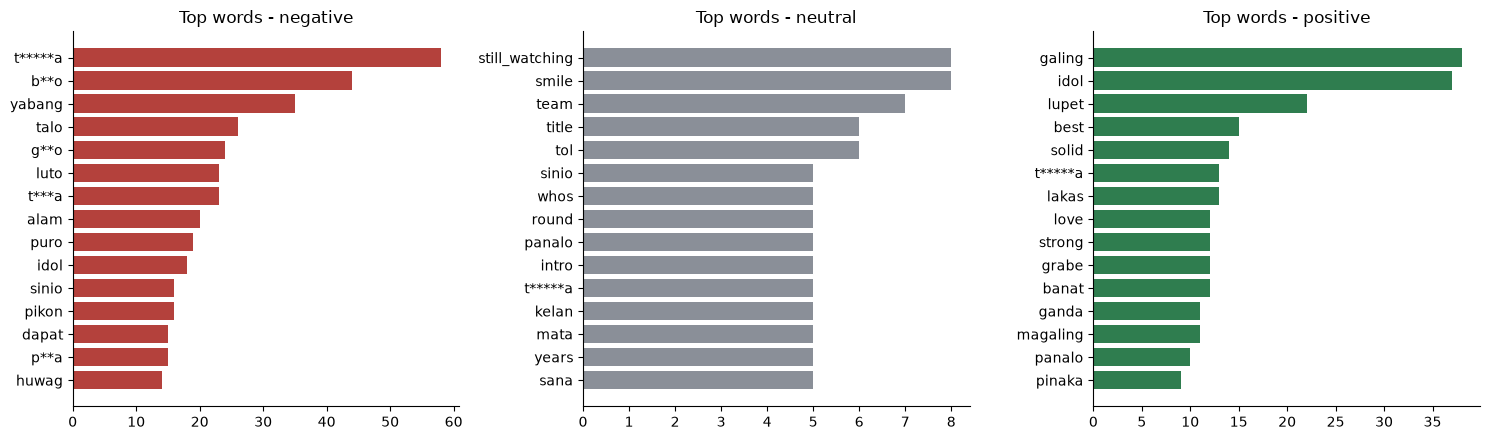

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, label in zip(axes, LABELS):
    top = word_counts[label].most_common(15)[::-1]
    ax.barh([mask(w) for w, _ in top], [c for _, c in top], color=COLORS[label])
    ax.set_title(f"Top words - {label}")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(config.CHARTS / "top_words_by_class.png", dpi=150)
plt.show()

## 6. Hard cases

30 short sentences written on purpose to be difficult (`data/labels/hard_cases.csv`): negation
("hindi magaling"), profanity used as praise ("t\*\*g i\*a ang lupet"), sarcasm, *pero / kaso* contrast,
questions, quoted bars and like-bait. Every model is also scored on these.

In [14]:
hard = data.load_hard_cases()
print(hard["label"].value_counts().to_dict())
mask_frame(hard[["hard_id", "text", "label", "phenomenon"]])

{'positive': 12, 'negative': 11, 'neutral': 7}


,hard_id,text,label,phenomenon
0,1,Hindi magaling si Loonie dito.,negative,negation
1,2,Hindi naman pangit yung laban eh.,positive,negation
2,3,Walang kwenta yung rebuttal nila.,negative,negation
3,4,Wala akong masabi sa galing ni Smugglaz.,positive,negation
4,5,T**g i*a ang lupet ng bara ni Abra!,positive,profanity_as_praise
5,6,"P*******a, ang bangis talaga ng round 3!",positive,profanity_as_praise
6,7,"G**o, pinakasolid na dos por dos 'to.",positive,profanity_as_praise
7,8,"Wow, ang galing mag-choke ni Shehyee. Idol talaga.",negative,sarcasm
8,9,"Ang husay naman ng judges, 7-0 agad. Sobrang fair talaga 🙄",negative,sarcasm
9,10,Ganda ng laban sana kaso luto.,negative,contrast


## 7. EDA notes (Day 1 summary)

- **Raw data:** 78,566 comments and replies scraped with the YouTube Data API (69,237 top-level, 9,329 replies),
  from the battle's upload in 2012 until 2026. Almost half were posted in 2012 alone; people still comment
  every year ("2024 still watching").
- **After cleaning:** 68,097 comments (empty, symbol-only and duplicate comments removed); 67,000 are short
  enough (≤ 400 characters) to model.
- **Language:** mostly Tagalog (~74%), then Taglish and English (~8% and ~7%); ~10% have no function words
  to tell (emoji, names only). Stock English tools will miss most of this text.
- **Labelled sample:** 1,000 random comments - 435 negative (43.5%), 325 positive (32.5%), 240 neutral (24%).
  Imbalanced, so **macro-F1** is the main metric.
- **Length:** negative comments are the longest (~85 characters on average; arguments and insults),
  neutral and positive are shorter (~60).
- **Vocabulary:** the most common curse word is the top negative word *and* a top-6 positive word
  (used as hype), so swear words alone don't decide the sentiment.
- **Fixed split:** stratified, seed 42 → 700 train / 300 test (131 negative, 72 neutral, 97 positive),
  saved once to `data/processed/` and never changed.